# EN4554 Assignment 2 - Task 1: Backpropagation

- **(a)** `LinearLayer`, `ReLULayer`, `SigmoidLayer`, `SoftmaxCrossEntropyLayer` with explicit forward/backward (no autograd), assembled into an `MLP`
- **(b)** Gradient verification against PyTorch autograd (`torch.allclose`) and centred finite differences, in float64, on real CIFAR-10 images
- **(c)** SGD training on flattened CIFAR-10: learning-rate / momentum comparison, train and validation loss, validation accuracy
- **(d)** Per-layer gradient norms at initialisation for a 10-layer MLP, sigmoid vs ReLU (with diagnostics and init ablations)


In [32]:
import math, time, random
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cpu


## Data Loading: CIFAR-10 (45k train / 5k val)

In [33]:
raw = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
X_all = torch.from_numpy(raw.data).float().div_(255).permute(0, 3, 1, 2).contiguous()   # (50000,3,32,32) in [0,1]
y_all = torch.tensor(raw.targets, dtype=torch.long)

perm = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45000], perm[45000:]
X_tr, y_tr = X_all[tr_idx], y_all[tr_idx]
X_va, y_va = X_all[va_idx], y_all[va_idx]
del X_all

# statistics from the 45k TRAINING split only (validation images are not used)
mean = X_tr.mean(dim=(0, 2, 3), keepdim=True)
std  = X_tr.std(dim=(0, 2, 3), keepdim=True)
print('Channel mean (train split):', [round(v, 4) for v in mean.flatten().tolist()])
print('Channel std  (train split):', [round(v, 4) for v in std.flatten().tolist()])

def prep(X):                       # normalise, flatten to (N, 3072), move to device
    return ((X - mean) / std).flatten(1).to(device)

X_tr, X_va = prep(X_tr), prep(X_va)
y_tr, y_va = y_tr.to(device), y_va.to(device)
print('Train:', tuple(X_tr.shape), '| Val:', tuple(X_va.shape),
      '| train mean/std after norm: %.3f / %.3f' % (X_tr.mean().item(), X_tr.std().item()))

Channel mean (train split): [0.4917, 0.4823, 0.4467]
Channel std  (train split): [0.2471, 0.2435, 0.2616]
Train: (45000, 3072) | Val: (5000, 3072) | train mean/std after norm: 0.000 / 1.000



## Task 1(a) - Manual Layers with Explicit Forward / Backward

In [34]:
class LinearLayer:
    """
    out = x W^T + b      W: (out, in)
    Backward: dW = d_out^T x,  db = sum(d_out),  dx = d_out W
    init: 'he'      N(0, 2/fan_in)
          'xavier'  N(0, 2/(fan_in+fan_out))
          'default' U(-1/sqrt(fan_in), +1/sqrt(fan_in))  (PyTorch nn.Linear default; variance 1/(3 fan_in), NOT He)
    """
    def __init__(self, in_features, out_features, init='he', dtype=torch.float32):
        if init == 'he':
            W = torch.randn(out_features, in_features) * math.sqrt(2.0 / in_features)
        elif init == 'xavier':
            W = torch.randn(out_features, in_features) * math.sqrt(2.0 / (in_features + out_features))
        elif init == 'default':
            W = (torch.rand(out_features, in_features) * 2 - 1) / math.sqrt(in_features)
        else:
            raise ValueError(init)
        self.W  = W.to(device=device, dtype=dtype).contiguous()
        self.b  = torch.zeros(out_features, device=device, dtype=dtype)
        self.dW = torch.zeros_like(self.W); self.db = torch.zeros_like(self.b)
        self._x = self._dout = None

    def forward(self, x):
        self._x = x
        return x @ self.W.T + self.b

    def backward(self, d_out):
        self._dout = d_out
        self.dW = d_out.T @ self._x
        self.db = d_out.sum(dim=0)
        return d_out @ self.W

    def params(self): return [(self.W, self.dW), (self.b, self.db)]


class ReLULayer:
    def forward(self, x):
        self._mask = (x > 0).to(x.dtype)
        return x * self._mask
    def backward(self, d_out): return d_out * self._mask
    def params(self): return []


class SigmoidLayer:
    def forward(self, x):
        self._y = torch.sigmoid(x)
        return self._y
    def backward(self, d_out): return d_out * self._y * (1.0 - self._y)
    def params(self): return []


class SoftmaxCrossEntropyLayer:
    """Stable softmax + mean cross-entropy. Backward: (softmax - one_hot) / N."""
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values
        logp = z - torch.logsumexp(z, dim=1, keepdim=True)
        self._p, self._y, self._N = logp.exp(), y, logits.shape[0]
        return -logp[torch.arange(self._N, device=logits.device), y].mean()
    def backward(self):
        d = self._p.clone()
        d[torch.arange(self._N, device=d.device), self._y] -= 1.0
        return d / self._N
    def params(self): return []


class MLP:
    """(Linear -> activation) x n_hidden -> Linear -> SoftmaxCE"""
    def __init__(self, layer_sizes, activation='relu', init='he', dtype=torch.float32):
        self.activation_type = activation
        self.layers = []
        for i in range(len(layer_sizes) - 1):
            self.layers.append(LinearLayer(layer_sizes[i], layer_sizes[i + 1], init, dtype))
            if i < len(layer_sizes) - 2:
                if activation == 'relu':      self.layers.append(ReLULayer())
                elif activation == 'sigmoid': self.layers.append(SigmoidLayer())
                else: raise ValueError(activation)
        self.loss_layer = SoftmaxCrossEntropyLayer()

    def linears(self): return [l for l in self.layers if isinstance(l, LinearLayer)]

    def forward(self, x, y=None):
        h = x
        for layer in self.layers: h = layer.forward(h)
        return h if y is None else self.loss_layer.forward(h, y)

    def backward(self):
        g = self.loss_layer.backward()
        for layer in reversed(self.layers): g = layer.backward(g)
        return g

    def params(self):
        return [p for l in self.layers for p in l.params()]

    def predict(self, x): return self.forward(x).argmax(dim=1)


class SGD:
    """Minibatch SGD; momentum=0 gives plain SGD: p <- p - lr * grad."""
    def __init__(self, lr, momentum=0.0): self.lr, self.mom, self.v = lr, momentum, None
    def step(self, mlp):
        ps = mlp.params()
        if self.v is None: self.v = [torch.zeros_like(p) for p, _ in ps]
        for v, (p, g) in zip(self.v, ps):
            v.mul_(self.mom).add_(g)
            p.sub_(self.lr * v)

@torch.no_grad()
def evaluate(mlp, X, y, bs=5000):
    loss_sum, correct = 0.0, 0
    for i in range(0, len(X), bs):
        lg = mlp.forward(X[i:i+bs])
        loss_sum += mlp.loss_layer.forward(lg, y[i:i+bs]).item() * len(lg)
        correct  += (lg.argmax(1) == y[i:i+bs]).sum().item()
    return loss_sum / len(X), 100.0 * correct / len(X)

print('Defined: LinearLayer, ReLULayer, SigmoidLayer, SoftmaxCrossEntropyLayer, MLP, SGD, evaluate')

Defined: LinearLayer, ReLULayer, SigmoidLayer, SoftmaxCrossEntropyLayer, MLP, SGD, evaluate


## Task 1(b) - Gradient verification

In [35]:
def rel_err(a, b):
    return (torch.norm(a - b) / (torch.norm(a) + torch.norm(b) + 1e-300)).item()


def autograd_grads(mlp, x, y):
    ps, h = [], x
    for l in mlp.layers:
        if isinstance(l, LinearLayer):
            W = l.W.clone().requires_grad_(True); b = l.b.clone().requires_grad_(True)
            ps += [W, b]; h = h @ W.T + b
        elif isinstance(l, ReLULayer): h = torch.relu(h)
        else:                          h = torch.sigmoid(h)
    F.cross_entropy(h, y).backward()
    return [p.grad for p in ps]

def fd_grad(mlp, x, y, tensor, idxs, eps=1e-6):
    flat = tensor.view(-1)                 # shares memory with the layer's parameter
    out = []
    for i in idxs:
        old = flat[i].item()
        flat[i] = old + eps; lp = mlp.forward(x, y).item()
        flat[i] = old - eps; lm = mlp.forward(x, y).item()
        flat[i] = old                      # restore exactly
        out.append((lp - lm) / (2 * eps))
    return torch.tensor(out, dtype=tensor.dtype, device=tensor.device)

def verify_gradients(sizes, activation='relu', n=32, eps=1e-6, n_fd=30):
    set_seed(0)
    mlp = MLP(sizes, activation, init='he', dtype=torch.float64)
    x, y = X_tr[:n].double(), y_tr[:n]
    mlp.forward(x, y); mlp.backward()
    mine   = [g.clone() for _, g in mlp.params()]
    tensors = [p for p, _ in mlp.params()]
    ref    = autograd_grads(mlp, x, y)
    names  = [f'{k}{i+1}' for i in range(len(mlp.linears())) for k in ('W', 'b')]

    g = torch.Generator().manual_seed(1)
    print(f'Network {sizes}, activation={activation}, float64, n={n}, eps={eps}')
    print(f"{'param':<6}{'shape':<14}{'relerr vs autograd':>20}{'allclose':>10}{'relerr vs FD':>16}{'allclose':>10}")
    ok_ag = ok_fd = True
    for name, m, r, t in zip(names, mine, ref, tensors):
        k = min(n_fd, t.numel())
        idxs = torch.randperm(t.numel(), generator=g)[:k].tolist()
        fd = fd_grad(mlp, x, y, t, idxs, eps)
        an = m.reshape(-1)[idxs]
        a1 = torch.allclose(m, r,  rtol=1e-7, atol=1e-10)
        a2 = torch.allclose(an, fd, rtol=1e-4, atol=1e-7)
        ok_ag &= a1; ok_fd &= a2
        print(f'{name:<6}{str(tuple(t.shape)):<14}{rel_err(m, r):>20.2e}{str(a1):>10}{rel_err(an, fd):>16.2e}{str(a2):>10}')
    print(f'  -> all match autograd: {ok_ag} | all match finite differences: {ok_fd}\n')

verify_gradients([3072, 64, 32, 10], 'relu')
verify_gradients([3072, 64, 48, 32, 16, 10], 'relu')
verify_gradients([3072, 64, 32, 10], 'sigmoid')

Network [3072, 64, 32, 10], activation=relu, float64, n=32, eps=1e-06
param shape           relerr vs autograd  allclose    relerr vs FD  allclose
W1    (64, 3072)                6.00e-17      True        3.78e-09      True
b1    (64,)                     4.87e-17      True        2.89e-09      True
W2    (32, 64)                  4.32e-17      True        2.82e-09      True
b2    (32,)                     3.94e-17      True        2.35e-09      True
W3    (10, 32)                  2.90e-17      True        1.46e-09      True
b3    (10,)                     3.45e-17      True        8.92e-10      True
  -> all match autograd: True | all match finite differences: True

Network [3072, 64, 48, 32, 16, 10], activation=relu, float64, n=32, eps=1e-06
param shape           relerr vs autograd  allclose    relerr vs FD  allclose
W1    (64, 3072)                6.23e-17      True        2.32e-09      True
b1    (64,)                     7.22e-17      True        2.77e-09      True
W2    (48, 64)

## Task 1(c) - Train the MLP on flattened CIFAR-10 with SGD

In [36]:
def train_mlp(sizes, lr, momentum=0.0, init='he', epochs=30, bs=128, seed=SEED, verbose=True):
    set_seed(seed)
    net, opt = MLP(sizes, 'relu', init), SGD(lr, momentum)
    N = len(X_tr)
    hist = dict(iter_loss=[], tr_loss=[], va_loss=[], va_acc=[])
    for ep in range(epochs):
        perm = torch.randperm(N, device=device)
        run = 0.0
        for i in range(0, N, bs):
            idx = perm[i:i+bs]
            loss = net.forward(X_tr[idx], y_tr[idx]); net.backward(); opt.step(net)
            hist['iter_loss'].append(loss.item()); run += loss.item() * len(idx)
        vl, va = evaluate(net, X_va, y_va)
        hist['tr_loss'].append(run / N); hist['va_loss'].append(vl); hist['va_acc'].append(va)
        if verbose and (ep == 0 or (ep + 1) % 5 == 0):
            print(f'  epoch {ep+1:2d}/{epochs}  train loss {run/N:.4f}  val loss {vl:.4f}  val acc {va:.2f}%')
    return net, hist

sizes = [3072, 512, 256, 10]
configs = [dict(lr=0.01, init='default'),          # baseline: PyTorch-default init, plain SGD
           dict(lr=0.01), dict(lr=0.03), dict(lr=0.1),
           dict(lr=0.01, momentum=0.9)]
results = {}
for cfg in configs:
    key = ', '.join(f'{k}={v}' for k, v in cfg.items())
    print('Training:', key); t0 = time.time()
    results[key] = train_mlp(sizes, **cfg)
    print(f'  finished in {time.time()-t0:.0f}s')

Training: lr=0.01, init=default
  epoch  1/30  train loss 2.0265  val loss 1.8531  val acc 35.74%
  epoch  5/30  train loss 1.5292  val loss 1.5391  val acc 45.96%
  epoch 10/30  train loss 1.3238  val loss 1.4114  val acc 50.90%
  epoch 15/30  train loss 1.1684  val loss 1.3923  val acc 51.20%
  epoch 20/30  train loss 1.0303  val loss 1.3552  val acc 52.62%
  epoch 25/30  train loss 0.8986  val loss 1.3706  val acc 54.06%
  epoch 30/30  train loss 0.7750  val loss 1.4593  val acc 51.98%
  finished in 320s
Training: lr=0.01
  epoch  1/30  train loss 1.8037  val loss 1.6692  val acc 41.34%
  epoch  5/30  train loss 1.3100  val loss 1.4825  val acc 49.28%
  epoch 10/30  train loss 1.0747  val loss 1.4393  val acc 50.24%
  epoch 15/30  train loss 0.8898  val loss 1.4642  val acc 50.12%
  epoch 20/30  train loss 0.7300  val loss 1.5091  val acc 50.20%
  epoch 25/30  train loss 0.5863  val loss 1.5702  val acc 51.92%
  epoch 30/30  train loss 0.4603  val loss 1.6646  val acc 50.74%
  finis

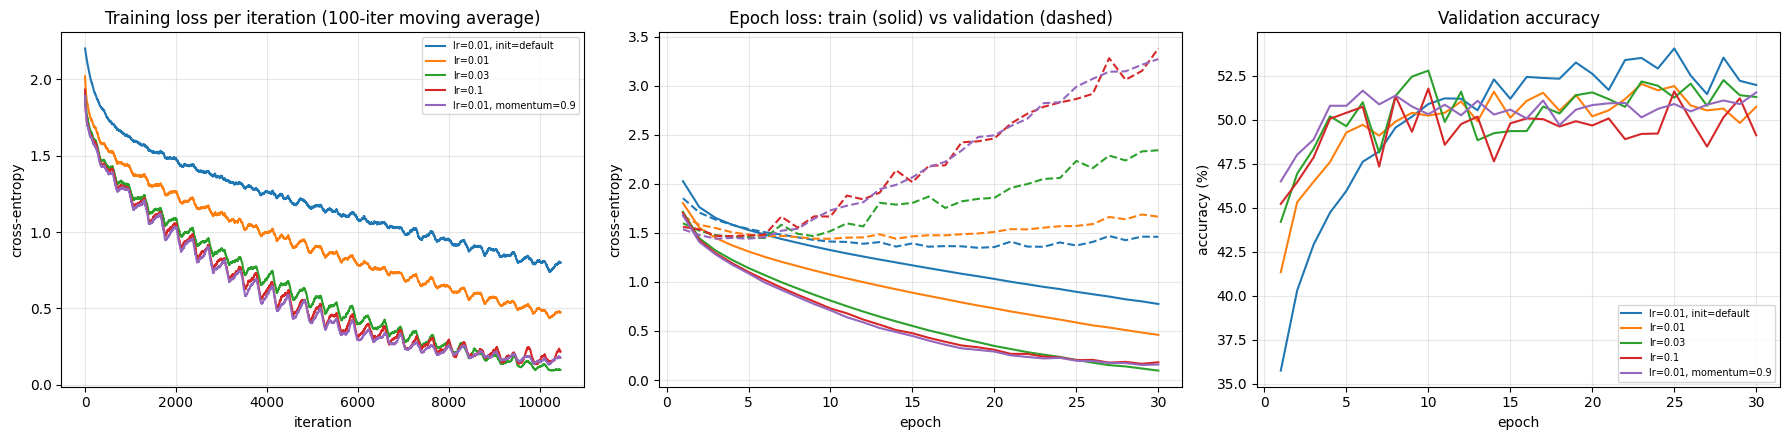

config                             train loss  val loss  final val acc  best val acc  min-val-loss epoch
lr=0.01, init=default                  0.7750    1.4593         51.98%        54.06%                  19
lr=0.01                                0.4603    1.6646         50.74%        52.04%                  10
lr=0.03                                0.0960    2.3414         51.30%        52.80%                   6
lr=0.1                                 0.1808    3.3789         49.12%        51.78%                   4
lr=0.01, momentum=0.9                  0.1583    3.2713         51.56%        51.66%                   3

Selected configuration (highest final validation accuracy): lr=0.01, init=default -> 51.98%


In [39]:
def smooth(v, k=100): return np.convolve(v, np.ones(k) / k, mode='valid')

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for key, (_, h) in results.items():
    ax[0].plot(smooth(h['iter_loss']), label=key)
    ep = range(1, len(h['tr_loss']) + 1)
    line, = ax[1].plot(ep, h['tr_loss'], label=key)
    ax[1].plot(ep, h['va_loss'], '--', color=line.get_color())
    ax[2].plot(ep, h['va_acc'], label=key)
ax[0].set(title='Training loss per iteration (100-iter moving average)', xlabel='iteration', ylabel='cross-entropy')
ax[1].set(title='Epoch loss: train (solid) vs validation (dashed)', xlabel='epoch', ylabel='cross-entropy')
ax[2].set(title='Validation accuracy', xlabel='epoch', ylabel='accuracy (%)')
for a in ax: a.grid(alpha=.3)
ax[0].legend(fontsize=7); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

print(f"{'config':<34}{'train loss':>11}{'val loss':>10}{'final val acc':>15}{'best val acc':>14}{'min-val-loss epoch':>20}")
for key, (_, h) in results.items():
    print(f"{key:<34}{h['tr_loss'][-1]:>11.4f}{h['va_loss'][-1]:>10.4f}{h['va_acc'][-1]:>14.2f}%{max(h['va_acc']):>13.2f}%{int(np.argmin(h['va_loss']))+1:>20d}")
best_key = max(results, key=lambda k: results[k][1]['va_acc'][-1])
best_net, best_hist = results[best_key]
print(f"\nSelected configuration (highest final validation accuracy): {best_key} -> {best_hist['va_acc'][-1]:.2f}%")

## Task 1(d) - Per-layer gradient norm at initialisation: sigmoid vs ReLU (10-layer MLP)

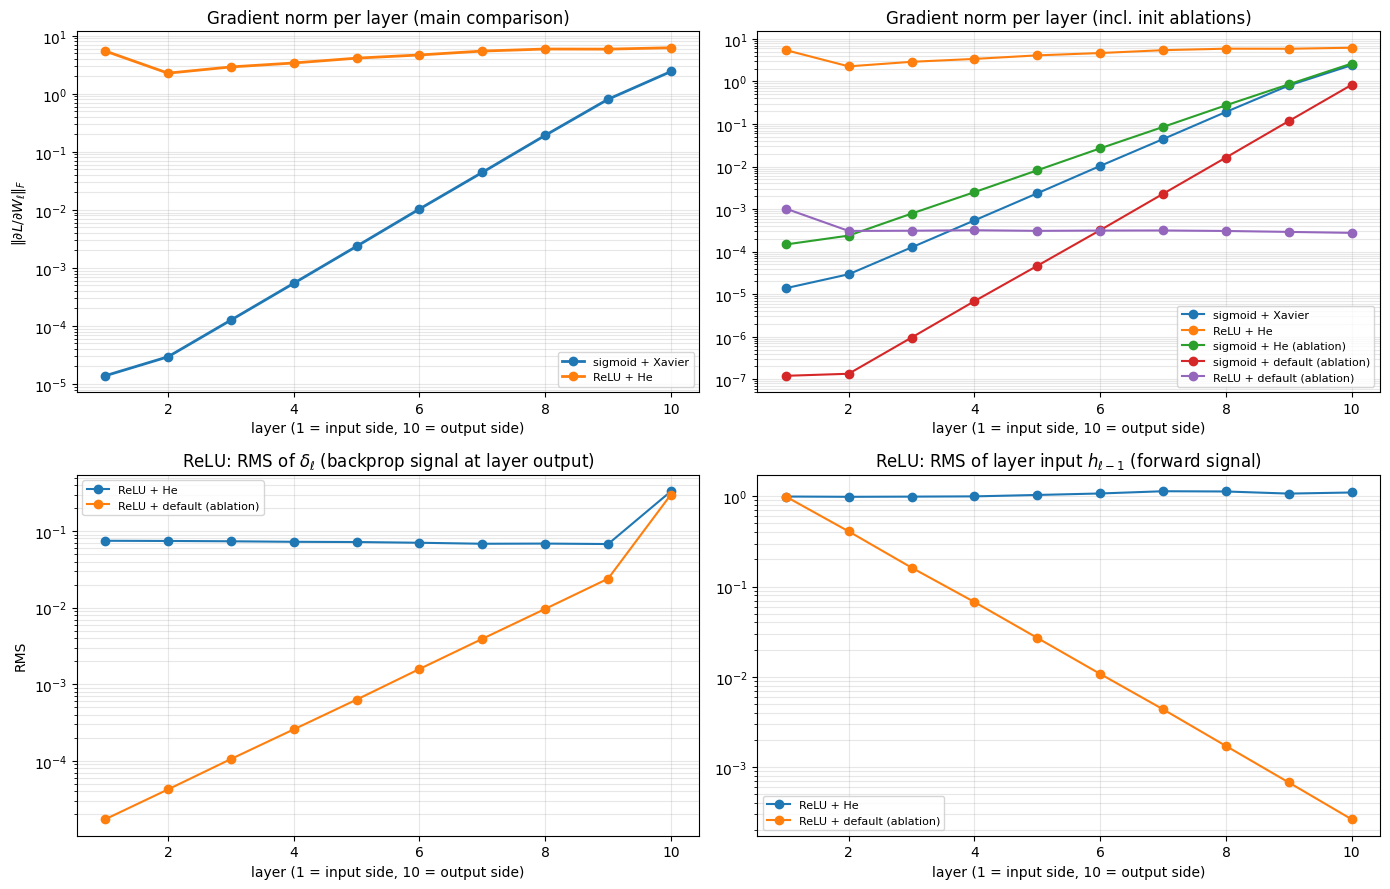

config                            layer 1    layer 5   layer 10     L10/L1 growth/layer*
sigmoid + Xavier                 1.38e-05   2.35e-03   2.42e+00   1.75e+05          4.12
ReLU + He                        5.47e+00   4.11e+00   6.22e+00   1.14e+00          1.13
sigmoid + He (ablation)          1.47e-04   8.18e-03   2.65e+00   1.79e+04          3.20
sigmoid + default (ablation)     1.20e-07   4.65e-05   8.36e-01   6.95e+06          7.07
ReLU + default (ablation)        1.03e-03   3.08e-04   2.76e-04   2.69e-01          0.99
*geometric-mean growth factor of the gradient norm per layer from layer 2 to layer 10 (layer 1 excluded: its fan-in is 3072, not 256).

ReLU + default init: delta RMS layer10 -> layer1 shrinks by 1.7e+04x | input RMS layer1 -> layer10 shrinks by 3.8e+03x


In [40]:
def layer_stats(activation, init, n_hidden=9, width=256, bs=256, n_batches=10, seeds=(0, 1, 2)):
    sizes = [3072] + [width] * n_hidden + [10]
    dW_n, h_rms, d_rms = [], [], []
    for s in seeds:
        set_seed(s)
        net = MLP(sizes, activation, init)
        g = torch.Generator(device=device).manual_seed(s)
        for _ in range(n_batches):
            idx = torch.randint(0, len(X_tr), (bs,), device=device, generator=g)
            net.forward(X_tr[idx], y_tr[idx]); net.backward()
            lins = net.linears()
            dW_n.append([l.dW.norm().item() for l in lins])
            h_rms.append([l._x.pow(2).mean().sqrt().item() for l in lins])
            d_rms.append([(l._dout * bs).pow(2).mean().sqrt().item() for l in lins])   # undo the 1/N in the loss
    return np.mean(dW_n, 0), np.mean(h_rms, 0), np.mean(d_rms, 0)

cfgs = {'sigmoid + Xavier': ('sigmoid', 'xavier'),
        'ReLU + He':        ('relu', 'he'),
        'sigmoid + He (ablation)':      ('sigmoid', 'he'),
        'sigmoid + default (ablation)': ('sigmoid', 'default'),
        'ReLU + default (ablation)':    ('relu', 'default')}
stats = {k: layer_stats(*v) for k, v in cfgs.items()}

L = np.arange(1, 11)
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for k in ('sigmoid + Xavier', 'ReLU + He'):
    ax[0, 0].semilogy(L, stats[k][0], 'o-', lw=2, label=k)
for k, v in stats.items():
    ax[0, 1].semilogy(L, v[0], 'o-', label=k)
for k in ('ReLU + He', 'ReLU + default (ablation)'):
    ax[1, 0].semilogy(L, stats[k][2], 'o-', label=k)
    ax[1, 1].semilogy(L, stats[k][1], 'o-', label=k)
ax[0, 0].set(title='Gradient norm per layer (main comparison)', ylabel=r'$\|\partial L/\partial W_\ell\|_F$')
ax[0, 1].set(title='Gradient norm per layer (incl. init ablations)')
ax[1, 0].set(title=r'ReLU: RMS of $\delta_\ell$ (backprop signal at layer output)', ylabel='RMS')
ax[1, 1].set(title=r'ReLU: RMS of layer input $h_{\ell-1}$ (forward signal)')
for a in ax.ravel(): a.set_xlabel('layer (1 = input side, 10 = output side)'); a.grid(alpha=.3, which='both'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'config':<30}{'layer 1':>11}{'layer 5':>11}{'layer 10':>11}{'L10/L1':>11}{'growth/layer*':>14}")
for k, (dw, _, _) in stats.items():
    print(f'{k:<30}{dw[0]:>11.2e}{dw[4]:>11.2e}{dw[9]:>11.2e}{dw[9]/dw[0]:>11.2e}{(dw[9]/dw[1])**(1/8):>14.2f}')
print('*geometric-mean growth factor of the gradient norm per layer from layer 2 to layer 10 (layer 1 excluded: its fan-in is 3072, not 256).')
print('\nReLU + default init: delta RMS layer10 -> layer1 shrinks by', f'{stats["ReLU + default (ablation)"][2][9]/stats["ReLU + default (ablation)"][2][0]:.1e}x',
      '| input RMS layer1 -> layer10 shrinks by', f'{stats["ReLU + default (ablation)"][1][0]/stats["ReLU + default (ablation)"][1][9]:.1e}x')